# 1.1 Análisis exploratorio

Actividad **1.1**:

1. Distribución de cada sensor por modelo de máquina.
2. Frecuencia de errores, mantenimientos y fallas por componente.
3. Comportamiento de la telemetría en las 48–72 h previas a una falla frente a periodos sanos.

El análisis usa el año completo para describir los datos. Ninguna decisión de modelado se ajusta con lo observado en noviembre–diciembre (prueba).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_all, SENSORS, COMPS, ERRORS, MODELS
from src.plots import set_style, savefig

set_style()
pd.set_option("display.precision", 3)
COMP_COLORS = dict(zip(COMPS, sns.color_palette("deep", 4)))

d = load_all()
tel, err, mnt, fail, mac = d["telemetry"], d["errors"], d["maint"], d["failures"], d["machines"]
assert len(tel) == 876_100 and tel["machineID"].nunique() == 100 and len(fail) == 761
{k: v.shape for k, v in d.items()}

{'telemetry': (876100, 6),
 'errors': (3919, 3),
 'maint': (3286, 3),
 'failures': (761, 3),
 'machines': (100, 3)}

## 1. Distribución de cada sensor por modelo de máquina

volt         rotate        pressure        vibration      
          mean    std    mean    std     mean    std      mean   std
model                                                               
model1  170.78  15.56  446.37  52.95   101.27  11.46     40.44  5.41
model2  170.72  15.51  446.81  52.53   101.22  11.38     40.39  5.38
model3  170.81  15.49  446.51  52.71   100.67  10.85     40.40  5.36
model4  170.77  15.50  446.71  52.57   100.67  10.86     40.34  5.36

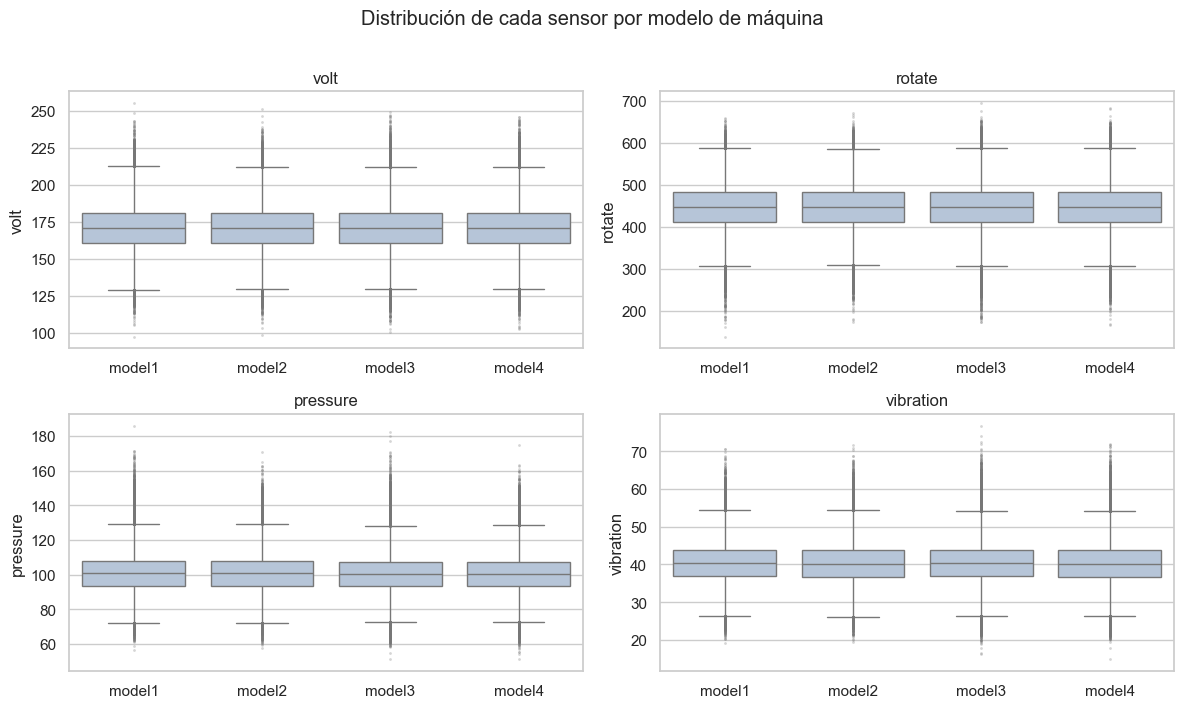

In [2]:
tel_m = tel.merge(mac, on="machineID")
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, s in zip(axes.flat, SENSORS):
    sns.boxplot(data=tel_m, x="model", y=s, order=MODELS, ax=ax, color="lightsteelblue",
                fliersize=1, flierprops=dict(alpha=0.3))
    ax.set(title=s, xlabel="")
fig.suptitle("Distribución de cada sensor por modelo de máquina", y=1.01)
plt.tight_layout()
savefig(fig, "01_sensors_by_model")

tel_m.groupby("model", observed=True)[SENSORS].agg(["mean", "std"]).round(2)

## 2. Frecuencia de errores, mantenimientos y fallas por componente

,reemplazos,fallas
comp1,804,192
comp2,863,259
comp3,808,131
comp4,811,179


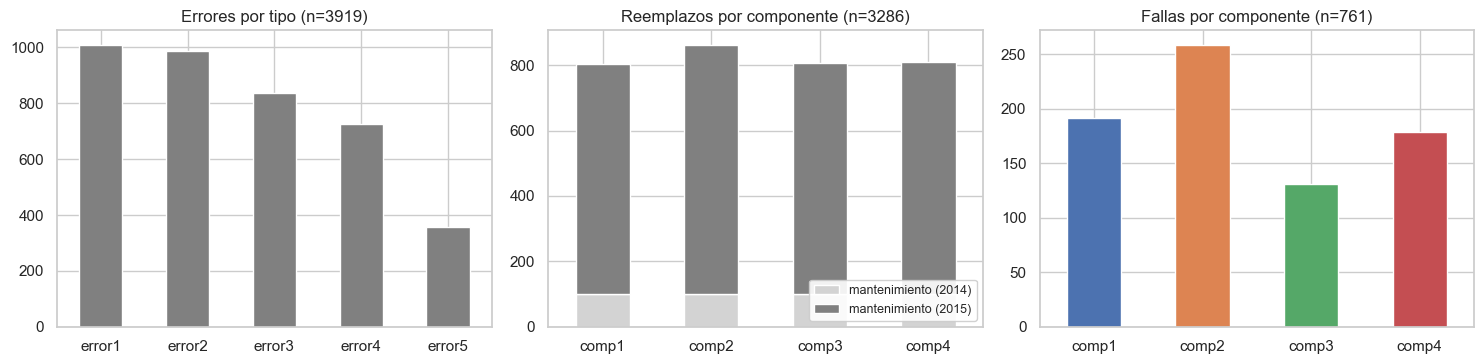

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
err["errorID"].value_counts().reindex(ERRORS).plot.bar(ax=axes[0], color="gray")
axes[0].set(title=f"Errores por tipo (n={len(err)})", xlabel="")
pd.DataFrame({
    "mantenimiento (2014)": mnt[mnt["datetime"] < "2015-01-01"]["comp"].value_counts(),
    "mantenimiento (2015)": mnt[mnt["datetime"] >= "2015-01-01"]["comp"].value_counts(),
}).reindex(COMPS).plot.bar(stacked=True, ax=axes[1], color=["lightgray", "gray"])
axes[1].set(title=f"Reemplazos por componente (n={len(mnt)})", xlabel="")
axes[1].legend(loc="lower right", fontsize=9, framealpha=0.9)
fail["failure"].value_counts().reindex(COMPS).plot.bar(ax=axes[2], color=[COMP_COLORS[c] for c in COMPS])
axes[2].set(title=f"Fallas por componente (n={len(fail)})", xlabel="")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
savefig(fig, "02_event_counts")

pd.DataFrame({
    "reemplazos": mnt["comp"].value_counts().reindex(COMPS),
    "fallas": fail["failure"].value_counts().reindex(COMPS),
})

## 3. Telemetría antes de una falla frente a periodos sanos

- **Ventana pre-falla:** para cada falla se toman las 72 h anteriores, alineadas por **horas hasta la falla**.
- **Horas sanas:** las que están a más de 7 días de cualquier falla o mantenimiento, antes o después.

In [4]:
HEALTHY_GAP = pd.Timedelta(days=7)
WINDOW = 72

events = pd.concat([fail[["machineID", "datetime"]], mnt[["machineID", "datetime"]]]).drop_duplicates()
events = events.rename(columns={"datetime": "t_ev"}).sort_values("t_ev")
t = tel.sort_values("datetime")
prev_ev = pd.merge_asof(t, events, left_on="datetime", right_on="t_ev", by="machineID", direction="backward")["t_ev"].values
next_ev = pd.merge_asof(t, events, left_on="datetime", right_on="t_ev", by="machineID", direction="forward")["t_ev"].values
far = pd.Timedelta(days=10_000)  # sin evento previo/siguiente cuenta como lejos
gap_prev = pd.Series(t["datetime"].values - prev_ev).fillna(far)
gap_next = pd.Series(next_ev - t["datetime"].values).fillna(far)
tel_h = t.assign(healthy=((gap_prev > HEALTHY_GAP) & (gap_next > HEALTHY_GAP)).values) \
    .sort_values(["machineID", "datetime"], ignore_index=True)
print(f"Horas sanas: {tel_h['healthy'].mean():.1%} de la telemetría")

tel_idx = tel_h.set_index(["machineID", "datetime"])
win = pd.DataFrame([
    (r.machineID, r.datetime - pd.Timedelta(hours=h), h, r.failure)
    for r in fail.itertuples() for h in range(WINDOW + 1)
], columns=["machineID", "datetime", "htf", "comp"]).join(tel_idx, on=["machineID", "datetime"])

Horas sanas: 17.6% de la telemetría


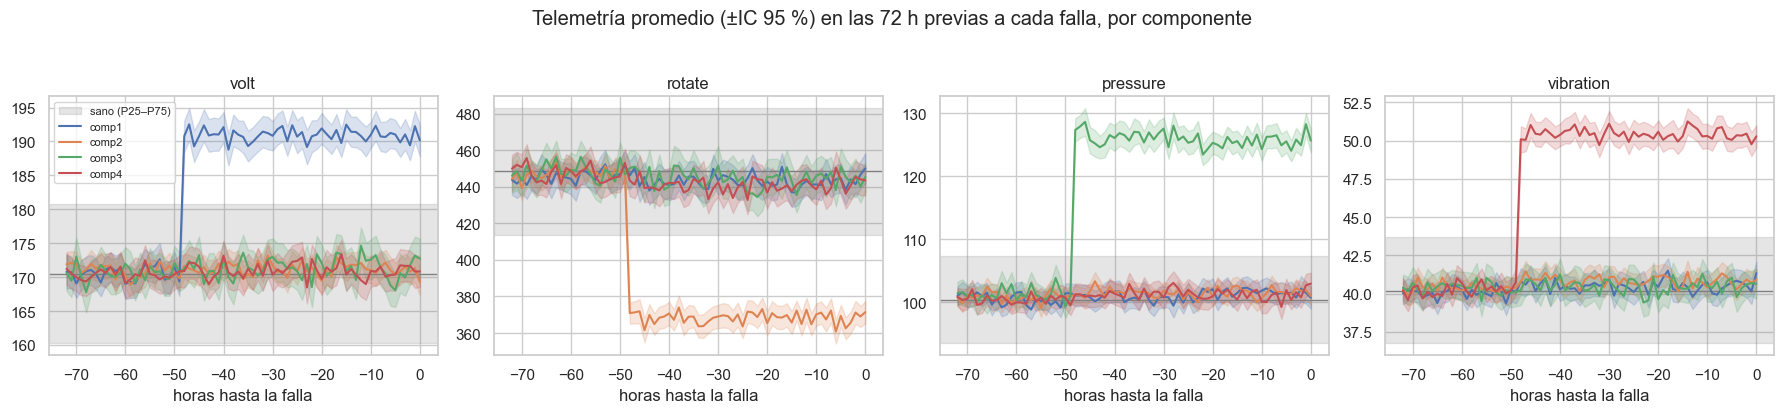

In [5]:
healthy = tel_h.loc[tel_h["healthy"], SENSORS]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True)
for ax, s in zip(axes, SENSORS):
    lo, med, hi = healthy[s].quantile([0.25, 0.5, 0.75])
    ax.axhspan(lo, hi, color="gray", alpha=0.2, label="sano (P25–P75)")
    ax.axhline(med, color="gray", lw=1)
    for c in COMPS:
        g = win[win["comp"] == c].groupby("htf")[s]
        m, se = g.mean(), g.sem()
        ax.plot(-m.index, m, color=COMP_COLORS[c], label=c)
        ax.fill_between(-m.index, m - 1.96 * se, m + 1.96 * se, color=COMP_COLORS[c], alpha=0.2)
    ax.set(title=s, xlabel="horas hasta la falla")
axes[0].legend(fontsize=8)
fig.suptitle("Telemetría promedio (±IC 95 %) en las 72 h previas a cada falla, por componente", y=1.03)
plt.tight_layout()
savefig(fig, "03_prefailure_signature")

In [6]:
# Cuantificación: media móvil de 24 h en las 48 h previas a la falla vs horas sanas (d de Cohen)
roll = tel_h.groupby("machineID")[SENSORS].rolling(24, min_periods=24).mean().reset_index(level=0, drop=True)
tel_h[[f"{s}_24h" for s in SENSORS]] = roll.values
pre = win.query("1 <= htf <= 48")[["machineID", "datetime", "comp"]].join(
    tel_h.set_index(["machineID", "datetime"])[[f"{s}_24h" for s in SENSORS]], on=["machineID", "datetime"])
healthy24 = tel_h.loc[tel_h["healthy"], [f"{s}_24h" for s in SENSORS]]

def cohens_d(a, b):
    a, b = a.dropna(), b.dropna()
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

pd.DataFrame({c: {s: cohens_d(pre.loc[pre["comp"] == c, f"{s}_24h"], healthy24[f"{s}_24h"]) for s in SENSORS}
              for c in COMPS}).style.format("{:+.2f}").background_gradient(cmap="RdBu_r", vmin=-3, vmax=3) \
    .set_caption("d de Cohen (48 h pre-falla − sano), media móvil 24 h")

,comp1,comp2,comp3,comp4
volt,+3.35,+0.13,+0.14,+0.08
rotate,-0.24,-3.61,-0.16,-0.37
pressure,+0.05,+0.16,+4.28,+0.11
vibration,+0.05,+0.22,+0.08,+3.78


## Hallazgos

- **Sensores por modelo.** Las distribuciones son prácticamente iguales entre los cuatro modelos: medias y desviaciones casi idénticas. El modelo de máquina no cambia el nivel de los sensores.
- **Frecuencias.**
  - Errores: error1 es el más frecuente y error5 el menos frecuente.
  - Reemplazos: están repartidos casi por igual entre componentes (≈ 800 cada uno).
  - Fallas: comp2 falla más (259) y comp3 menos (131).
  - Fallas y reemplazos se registran casi siempre a las 06:00.
- **Pre-falla vs sano.** Cada componente tiene una firma en un solo sensor:

  | componente | sensor | cambio |
  |---|---|---|
  | comp1 | volt | sube |
  | comp2 | rotate | baja |
  | comp3 | pressure | sube |
  | comp4 | vibration | sube |

  El cambio es un **escalón unas 48 h antes** de la falla y se mantiene hasta ella; entre 48 y 72 h antes no hay diferencia con los periodos sanos. Los d de Cohen son grandes (|d| > 3) en la pareja componente–sensor y ≈ 0 en las demás.